# Segmentación por Valor y Frecuencia (modelo de 2 ejes + estado)

Implementa el modelo propuesto: dos capas de naturaleza distinta que comparten la misma base, para que una sola segmentación sirva tanto para medir LTV como para accionar en CRM.

- **Capa estructural (estable):** cada cliente tiene un **Valor** (margen de contribución acumulado de toda su vida) y una **Frecuencia** (compras por año de vida). El número de niveles de cada eje no se fija a mano: lo determina el **método del codo** sobre esa variable. Los ejes se cruzan (ej. 3 metales × 3 niveles de frecuencia = 9 grupos estructurales).
- **Capa de estado (dinámica):** cada grupo estructural tiene su propio **umbral de muerte** (percentil 90 de los intervalos entre compras de sus clientes). El estado de un cliente (Activo / Por inactivar / Inactivo) se calcula comparando su recencia contra el umbral de *su propio grupo*, no contra una ventana fija de 12 meses igual para todos.

In [1]:
import time
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import urllib
import os
from dotenv import load_dotenv
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

load_dotenv()
sns.set_theme(style="whitegrid")

In [2]:
params = urllib.parse.quote_plus(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={os.getenv('DB_SERVER')};"
    "DATABASE=Ventas_Comerssia;"
    f"UID={os.getenv('DB_USER')};"
    f"PWD={os.getenv('DB_PASSWORD')};"
)

engine = create_engine(
    f"mssql+pyodbc:///?odbc_connect={params}",
    pool_pre_ping=True,
    pool_recycle=180,
)


def leer_con_reintentos(query, engine, intentos=4, espera=10):
    """Reintenta la consulta con una conexión nueva cada vez (protege contra
    cortes de red/VPN, sobre todo después de un cómputo largo en Python)."""
    for intento in range(1, intentos + 1):
        try:
            return pd.read_sql(query, engine)
        except Exception as e:
            engine.dispose()
            if intento == intentos:
                raise
            print(f"Intento {intento}/{intentos} falló ({type(e).__name__}); reintentando en {espera}s...")
            time.sleep(espera)

In [3]:
fecha_corte = pd.to_datetime("2026-08-31")

PERCENTIL_UMBRAL = 90        # percentil de los intervalos entre compras que define "muerte" del grupo
CORTE_ACTIVO = 0.7           # Activo si recencia < CORTE_ACTIVO * umbral_grupo
K_RANGE = range(2, 7)        # niveles a probar con el método del codo (2 a 6), por eje
MIN_INTERVALOS_CONFIABLE = 30  # bajo este número de intervalos, el umbral del grupo se considera poco confiable
AÑOS_VIDA_MINIMO = 30 / 365.25  # piso de 1 mes para años de vida (evita Frecuencia -> infinito en clientes nuevos)

METALES = ["Diamante","Oro", "Plata", "Bronce","Cobre"]
NIVELES_FRECUENCIA = ["Alta", "Media", "Baja", "Muy Baja", "Mínima"]

## 1. Extracción de datos (historial completo, no una ventana)

El LTV necesita la vida completa del cliente, no una ventana de 12 o 24 meses — por eso aquí se trae **todo** el historial de `Ventas_Unificadas` (la llave única cubre cohortes desde 2019). Es una consulta más pesada que la del notebook de K-Means.

In [4]:
import pathlib

# Se trae por año en vez de una sola consulta de ~2.5M filas: si la red se corta a medio
# camino, solo se pierde el año en curso, no todo. Los años ya cerrados quedan cacheados en
# disco (parquet); el año en curso NUNCA se cachea porque su ventana sigue abierta (si
# fecha_corte avanza el mes que viene, hay que volver a traerlo completo).
CACHE_DIR = pathlib.Path("cache_ventas_historico")
CACHE_DIR.mkdir(exist_ok=True)

COLUMNAS = ["ID_Cliente_Unico", "Pedido", "Fecha", "Cantidad", "Venta_Neta", "Costo_Promedio"]

# Cuentas genéricas / de canal / de prueba que NO son clientes reales -- se excluyen por
# Cliente (no por ID_Cliente_Unico) porque un mismo ID_Cliente_Unico puede traer mezclado
# un cliente real con uno genérico (ej. ID 206829 mezclaba a Catalina Gómez Barrera con
# "Consumidor Final"). Revisar/actualizar esta lista periódicamente.
CLIENTES_EXCLUIR = [
    "C222222222222", "C22222222222", "CN",                       # Consumidor Final
    "C111", "C1111111111",                                        # Genérico
    "C77", "C777", "C1020718323", "C1054709410",                  # Rappi
    "C1126257299", "C3104630926", "C4228907",
    "C000000000", "C000111000", "C01239874560", "C1037663367",    # Cuentas de prueba internas
    "C1122334455", "C11223344551", "C12235456", "C123456",
    "C192837465", "C1234563", "C1234567", "C12345677",
    "C12345678919", "C12345698", "C21299799", "C987789",
    "C34567", "C45789987", "C900343678", "C900790149",
    "C999999999", "C9999999999", "C99999999999",
]
clientes_excluir_sql = ", ".join(f"'{c}'" for c in CLIENTES_EXCLUIR)

# SKU con Costo_Promedio corrupto (filas duplicadas con costo unitario absurdo) -- excluir
# hasta que se corrija en el origen.
SKUS_EXCLUIR = ["2069"]
skus_excluir_sql = ", ".join(f"'{s}'" for s in SKUS_EXCLUIR)

# Canales cuyo Costo_Promedio no es confiable todavía -- excluir mientras se corrige.
CANALES_EXCLUIR = ["Shopify", "CHATCENTER WEB"]
canales_excluir_sql = ", ".join(f"'{c}'" for c in CANALES_EXCLUIR)

partes = []
for año in range(2019, fecha_corte.year + 1):
    cache_file = CACHE_DIR / f"ventas_{año}.parquet"
    año_en_curso = año == fecha_corte.year

    if cache_file.exists() and not año_en_curso:
        parte = pd.read_parquet(cache_file)
        print(f"  {año}: {len(parte):,} filas (desde caché)")
    else:
        query_año = f"""
        SELECT {', '.join(COLUMNAS)}
        FROM Ventas_Comerssia.dbo.Ventas_Unificadas
        WHERE ID_Cliente_Unico IS NOT NULL
          AND YEAR(Fecha) = {año}
          AND Fecha <= '{fecha_corte:%Y-%m-%d}'
          AND Cliente NOT IN ({clientes_excluir_sql})
          AND Sku NOT IN ({skus_excluir_sql})
          AND Canal NOT IN ({canales_excluir_sql})
        """
        parte = leer_con_reintentos(query_año, engine)
        if not año_en_curso:
            parte.to_parquet(cache_file, index=False)
        estado_cache = "año en curso, no se cachea" if año_en_curso else "descargadas"
        print(f"  {año}: {len(parte):,} filas ({estado_cache})")
    partes.append(parte)

df_ventas = pd.concat(partes, ignore_index=True)
df_ventas["Fecha"] = pd.to_datetime(df_ventas["Fecha"], errors="coerce")
print(f"Filas: {len(df_ventas):,} | Clientes únicos: {df_ventas['ID_Cliente_Unico'].nunique():,}")

  2019: 146,369 filas (descargadas)


  2020: 249,283 filas (descargadas)


  2021: 308,472 filas (descargadas)


  2022: 365,287 filas (descargadas)


  2023: 370,645 filas (descargadas)


  2024: 341,192 filas (descargadas)


  2025: 319,834 filas (descargadas)


  2026: 161,175 filas (año en curso, no se cachea)


Filas: 2,262,257 | Clientes únicos: 273,517


## 2. Margen de contribución por transacción

`Ventas_Unificadas` no trae una columna de margen ya calculada, así que se arma con lo que sí existe:

**Margen = Venta_Neta − (Costo_Promedio × Cantidad)**

- `Venta_Neta` ya viene sin IVA (se verificó contra `Venta`: `Venta_Neta ≈ Venta / 1.19`), y las devoluciones ya están como filas con `Cantidad` negativa (no hay tabla aparte de devoluciones) — al sumar, se restan solas.
- `Costo_Promedio` es el costo unitario, por eso se multiplica por `Cantidad` para obtener el costo de la línea.

In [5]:
df_ventas["Margen"] = df_ventas["Venta_Neta"] - (df_ventas["Costo_Promedio"].fillna(0) * df_ventas["Cantidad"])

## 3. Variables por cliente: Valor, Frecuencia, cosecha y recencia

In [6]:
clientes = (
    df_ventas.groupby("ID_Cliente_Unico")
    .agg(
        CosechaFecha=("Fecha", "min"),
        UltimaCompra=("Fecha", "max"),
        Valor=("Margen", "sum"),
        n_compras=("Pedido", "nunique"),
    )
    .reset_index()
)

años_vida = (fecha_corte - clientes["CosechaFecha"]).dt.days / 365.25
clientes["AñosVida"] = años_vida.clip(lower=AÑOS_VIDA_MINIMO)
clientes["Frecuencia"] = clientes["n_compras"] / clientes["AñosVida"]
clientes["RecenciaMeses"] = (fecha_corte - clientes["UltimaCompra"]).dt.days / 30.44

clientes = clientes[clientes["n_compras"] > 0].reset_index(drop=True)
print(f"Clientes con al menos una compra: {len(clientes):,}")
clientes[["Valor", "Frecuencia", "RecenciaMeses"]].describe()

Clientes con al menos una compra: 273,517


,Valor,Frecuencia,RecenciaMeses
count,2.735170e+05,273517.000000,273517.000000
mean,4.544644e+05,1.012856,33.173693
std,1.111622e+06,1.647892,24.179720
min,-9.726101e+05,0.142899,0.000000
25%,7.223201e+04,0.275869,10.709593
50%,1.666831e+05,0.534773,30.059133
75%,4.070224e+05,1.111308,51.379763
max,8.990810e+07,100.743838,83.968463


## 4. Eje de Valor — método del codo


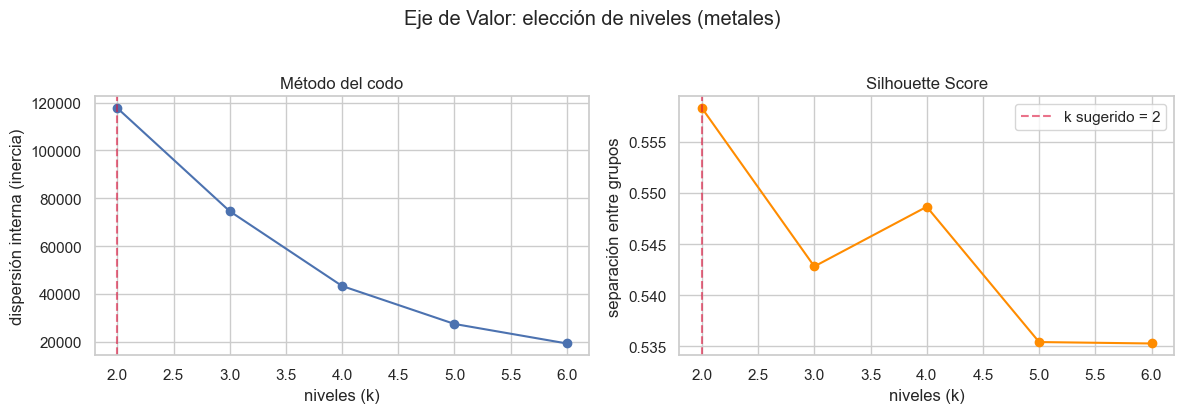

k=2: silhouette=0.558  <-- sugerido
k=3: silhouette=0.543
k=4: silhouette=0.549
k=5: silhouette=0.535
k=6: silhouette=0.535


In [7]:
def elegir_niveles(valores, k_range=K_RANGE, n_init=8):
    """Aplica el método del codo (+ silhouette) a una variable 1D.
    Devuelve (inercias, silhouettes, k_sugerido, transformador, X)"""
    x_t = np.arcsinh(valores.to_numpy()).reshape(-1, 1)
    scaler = StandardScaler()
    X = scaler.fit_transform(x_t)

    inertias, silhouettes = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=n_init)
        labels = km.fit_predict(X)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X, labels))

    k_sugerido = list(k_range)[int(np.argmax(silhouettes))]
    return inertias, silhouettes, k_sugerido, scaler, X


def graficar_codo(k_range, inertias, silhouettes, k_sugerido, titulo, archivo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(list(k_range), inertias, marker="o")
    axes[0].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6)
    axes[0].set_title("Método del codo")
    axes[0].set_xlabel("niveles (k)")
    axes[0].set_ylabel("dispersión interna (inercia)")

    axes[1].plot(list(k_range), silhouettes, marker="o", color="darkorange")
    axes[1].axvline(k_sugerido, color="crimson", linestyle="--", alpha=0.6, label=f"k sugerido = {k_sugerido}")
    axes[1].set_title("Silhouette Score")
    axes[1].set_xlabel("niveles (k)")
    axes[1].set_ylabel("separación entre grupos")
    axes[1].legend()

    fig.suptitle(titulo, y=1.03)
    fig.tight_layout()
    fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()


inertias_v, silhouettes_v, k_valor, scaler_valor, X_valor = elegir_niveles(clientes["Valor"])
graficar_codo(
    K_RANGE, inertias_v, silhouettes_v, k_valor,
    "Eje de Valor: elección de niveles (metales)",
    "grafico_1_codo_valor.png",
)
for k, s in zip(K_RANGE, silhouettes_v):
    marca = "  <-- sugerido" if k == k_valor else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

## 5. Eje de Frecuencia — método del codo

**Gráfico 2.** Mismo procedimiento sobre la Frecuencia (compras por año de vida).

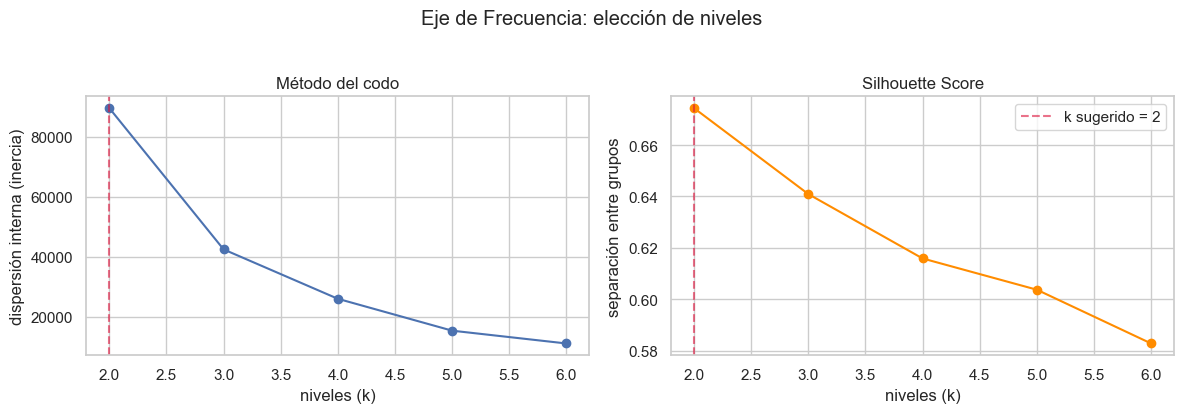

k=2: silhouette=0.674  <-- sugerido
k=3: silhouette=0.641
k=4: silhouette=0.616
k=5: silhouette=0.604
k=6: silhouette=0.583


In [8]:
inertias_f, silhouettes_f, k_frecuencia, scaler_frec, X_frec = elegir_niveles(clientes["Frecuencia"])
graficar_codo(
    K_RANGE, inertias_f, silhouettes_f, k_frecuencia,
    "Eje de Frecuencia: elección de niveles",
    "grafico_2_codo_frecuencia.png",
)
for k, s in zip(K_RANGE, silhouettes_f):
    marca = "  <-- sugerido" if k == k_frecuencia else ""
    print(f"k={k}: silhouette={s:.3f}{marca}")

## 6. Niveles finales y etiquetas

Si el negocio requiere otro número de niveles en algún eje (por ejemplo, para calzar con la nomenclatura de metales ya conocida), sobrescribir `K_VALOR` / `K_FRECUENCIA` aquí.

In [9]:
K_VALOR = 3            # <-- sobrescribe con un entero si el negocio prefiere otro número de metales
K_FRECUENCIA = 3   # <-- sobrescribe con un entero si el negocio prefiere otro número de niveles

km_valor = KMeans(n_clusters=K_VALOR, random_state=42, n_init=8)
clientes["Cluster_Valor"] = km_valor.fit_predict(X_valor)

km_frec = KMeans(n_clusters=K_FRECUENCIA, random_state=42, n_init=8)
clientes["Cluster_Frecuencia"] = km_frec.fit_predict(X_frec)

orden_valor = clientes.groupby("Cluster_Valor")["Valor"].mean().sort_values(ascending=False).index.tolist()
mapa_metal = {c: METALES[i] if i < len(METALES) else f"Nivel Valor {i+1}" for i, c in enumerate(orden_valor)}

orden_frec = clientes.groupby("Cluster_Frecuencia")["Frecuencia"].mean().sort_values(ascending=False).index.tolist()
mapa_frecuencia = {c: NIVELES_FRECUENCIA[i] if i < len(NIVELES_FRECUENCIA) else f"Nivel Frec {i+1}" for i, c in enumerate(orden_frec)}

clientes["Metal"] = clientes["Cluster_Valor"].map(mapa_metal)
clientes["NivelFrecuencia"] = clientes["Cluster_Frecuencia"].map(mapa_frecuencia)
clientes["GrupoEstructural"] = clientes["Metal"] + " / " + clientes["NivelFrecuencia"]

orden_metales = [mapa_metal[c] for c in orden_valor]
orden_niveles_frec = [mapa_frecuencia[c] for c in orden_frec]

print(f"Metales (Valor): {orden_metales}")
print(f"Niveles (Frecuencia): {orden_niveles_frec}")
print(f"Grupos estructurales: {K_VALOR} x {K_FRECUENCIA} = {K_VALOR * K_FRECUENCIA} posibles")
clientes["GrupoEstructural"].value_counts()

Metales (Valor): ['Diamante', 'Oro', 'Plata']
Niveles (Frecuencia): ['Alta', 'Media', 'Baja']
Grupos estructurales: 3 x 3 = 9 posibles


GrupoEstructural
Oro / Baja          85481
Plata / Baja        79102
Diamante / Media    32693
Oro / Media         29833
Diamante / Baja     12411
Diamante / Alta     11521
Plata / Media       11020
Oro / Alta           7413
Plata / Alta         4043
Name: count, dtype: int64

In [ ]:
# Rango de Valor y Frecuencia por nivel -- listo para copiar a un documento

def fmt_cop(valor):
    return "$" + f"{valor:,.0f}".replace(",", ".")


tabla_valor = (
    clientes.groupby("Metal")["Valor"]
    .agg(["min", "max", "mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
tabla_valor_fmt = tabla_valor.copy()
for col in ["min", "max", "mean", "median"]:
    tabla_valor_fmt[col] = tabla_valor[col].apply(fmt_cop)

tabla_frecuencia = (
    clientes.groupby("NivelFrecuencia")["Frecuencia"]
    .agg(["min", "max", "mean", "median", "count"])
    .sort_values("mean", ascending=False)
)
tabla_frecuencia_fmt = tabla_frecuencia.copy()
for col in ["min", "max", "mean", "median"]:
    tabla_frecuencia_fmt[col] = tabla_frecuencia[col].map(lambda v: f"{v:.2f}")

print("Rango de Valor (margen) por Metal")
print(tabla_valor_fmt.to_string())
print()
print("Rango de Frecuencia (compras/año) por Nivel de Frecuencia")
print(tabla_frecuencia_fmt.to_string())

## 7. Distribución de Valor y Frecuencia con los cortes encontrados

**Gráfico 3.** Dónde caen los cortes entre niveles sobre la distribución real — permite validar que los grupos tengan sentido de negocio y no queden vacíos o minúsculos.

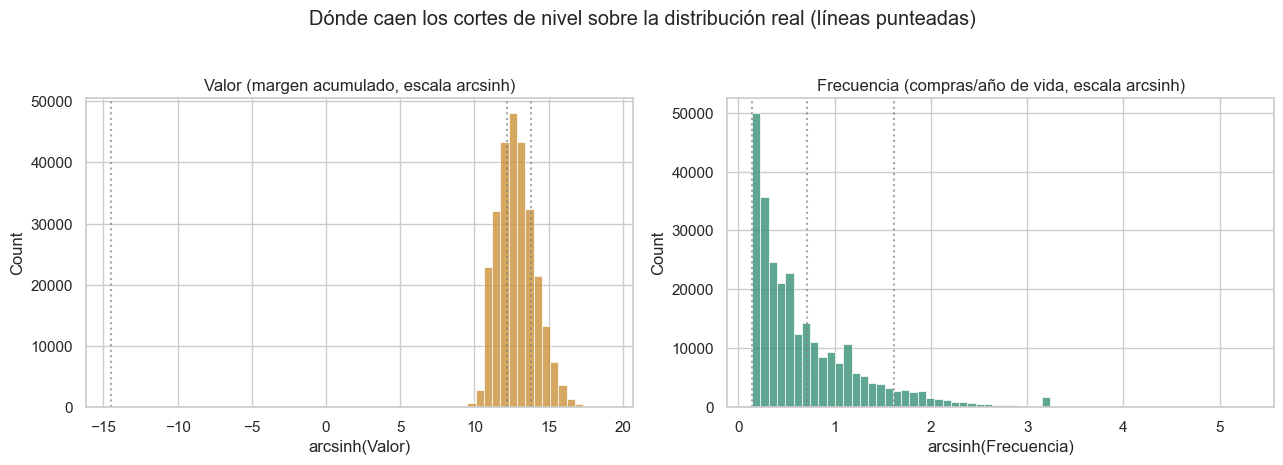

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(np.arcsinh(clientes["Valor"]), bins=60, ax=axes[0], color="#c98a2b")
for metal in orden_metales:
    corte = np.arcsinh(clientes.loc[clientes["Metal"] == metal, "Valor"].min())
    axes[0].axvline(corte, color="grey", linestyle=":", alpha=0.7)
axes[0].set_title("Valor (margen acumulado, escala arcsinh)")
axes[0].set_xlabel("arcsinh(Valor)")

sns.histplot(np.arcsinh(clientes["Frecuencia"]), bins=60, ax=axes[1], color="#2b8a6f")
for nivel in orden_niveles_frec:
    corte = np.arcsinh(clientes.loc[clientes["NivelFrecuencia"] == nivel, "Frecuencia"].min())
    axes[1].axvline(corte, color="grey", linestyle=":", alpha=0.7)
axes[1].set_title("Frecuencia (compras/año de vida, escala arcsinh)")
axes[1].set_xlabel("arcsinh(Frecuencia)")

fig.suptitle("Dónde caen los cortes de nivel sobre la distribución real (líneas punteadas)", y=1.03)
fig.tight_layout()
fig.savefig("grafico_3_distribucion_cortes.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Cruce de ejes: los grupos estructurales

**Gráfico 4.** Igual que en la propuesta: no son 27 grupos fijos ni una tabla arbitraria — son el cruce real de los niveles encontrados en cada eje, con la cantidad de clientes y el % del margen total que concentra cada celda.

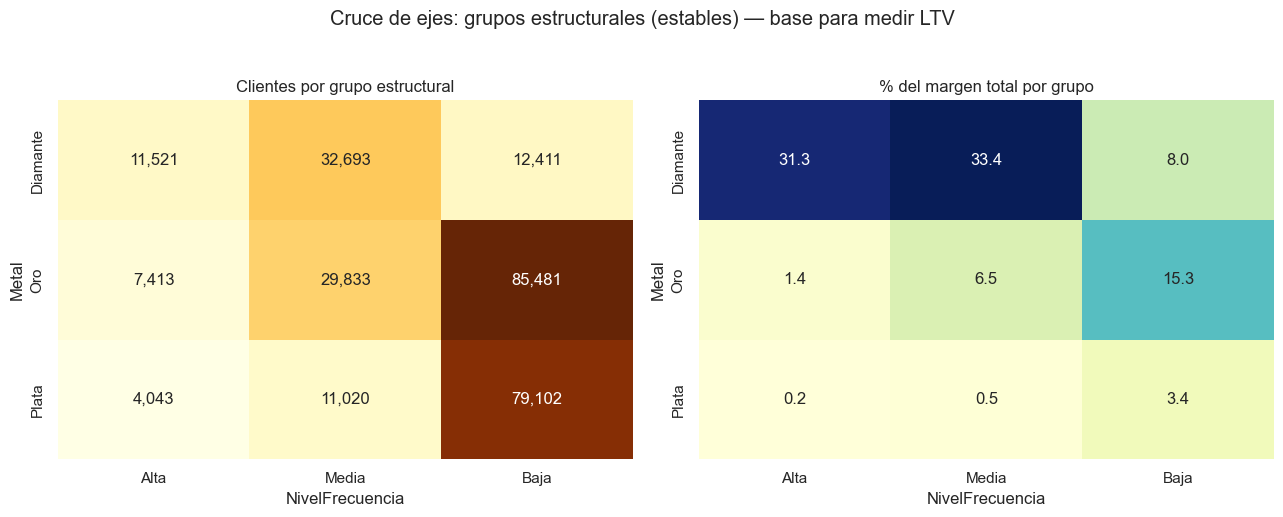

In [11]:
tabla_clientes = clientes.pivot_table(
    index="Metal", columns="NivelFrecuencia", values="ID_Cliente_Unico", aggfunc="count", fill_value=0
).reindex(index=orden_metales, columns=orden_niveles_frec)

tabla_margen_pct = clientes.pivot_table(
    index="Metal", columns="NivelFrecuencia", values="Valor", aggfunc="sum", fill_value=0
).reindex(index=orden_metales, columns=orden_niveles_frec)
tabla_margen_pct = tabla_margen_pct / clientes["Valor"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(tabla_clientes, annot=True, fmt=",", cmap="YlOrBr", ax=axes[0], cbar=False)
axes[0].set_title("Clientes por grupo estructural")

sns.heatmap(tabla_margen_pct, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1], cbar=False)
axes[1].set_title("% del margen total por grupo")

fig.suptitle("Cruce de ejes: grupos estructurales (estables) — base para medir LTV", y=1.03)
fig.tight_layout()
fig.savefig("grafico_4_cruce_grupos.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Umbral de vida por grupo (percentil 90 de intervalos entre compras)

Solo los clientes con 2 o más compras generan intervalos observables. Para cada grupo estructural se junta la distribución de esos intervalos y se toma el percentil 90 — ese es el umbral de "muerte" propio de ese grupo.

In [12]:
fechas_pedido = (
    df_ventas.groupby(["ID_Cliente_Unico", "Pedido"])["Fecha"].min().reset_index()
    .sort_values(["ID_Cliente_Unico", "Fecha"])
)
fechas_pedido["Intervalo_Meses"] = (
    fechas_pedido.groupby("ID_Cliente_Unico")["Fecha"].diff().dt.days / 30.44
)
intervalos = fechas_pedido.dropna(subset=["Intervalo_Meses"])[["ID_Cliente_Unico", "Intervalo_Meses"]]
intervalos = intervalos.merge(clientes[["ID_Cliente_Unico", "GrupoEstructural"]], on="ID_Cliente_Unico", how="left")

umbral_global = np.percentile(intervalos["Intervalo_Meses"], PERCENTIL_UMBRAL)

umbrales = (
    intervalos.groupby("GrupoEstructural")["Intervalo_Meses"]
    .agg(n_intervalos="count", Umbral_Meses=lambda s: np.percentile(s, PERCENTIL_UMBRAL))
    .reset_index()
)
umbrales["Confiable"] = umbrales["n_intervalos"] >= MIN_INTERVALOS_CONFIABLE
umbrales.loc[~umbrales["Confiable"], "Umbral_Meses"] = umbral_global

print(f"Umbral global (fallback): {umbral_global:.1f} meses")
umbrales.sort_values("Umbral_Meses")

Umbral global (fallback): 21.1 meses


,GrupoEstructural,n_intervalos,Umbral_Meses,Confiable
6,Plata / Alta,502,4.793035,True
3,Oro / Alta,5977,6.668857,True
0,Diamante / Alta,190383,7.030223,True
8,Plata / Media,2060,15.906702,True
2,Diamante / Media,204243,18.134034,True
5,Oro / Media,57537,21.616294,True
1,Diamante / Baja,24281,39.848883,True
7,Plata / Baja,9198,43.538108,True
4,Oro / Baja,68072,43.692510,True


**Gráfico 5.** Distribución de intervalos entre compras para los 4 grupos con más clientes, con su percentil 90 marcado — el mismo silencio (ej. 5 meses) puede ser normal en un grupo de baja frecuencia y anómalo en uno de alta frecuencia.

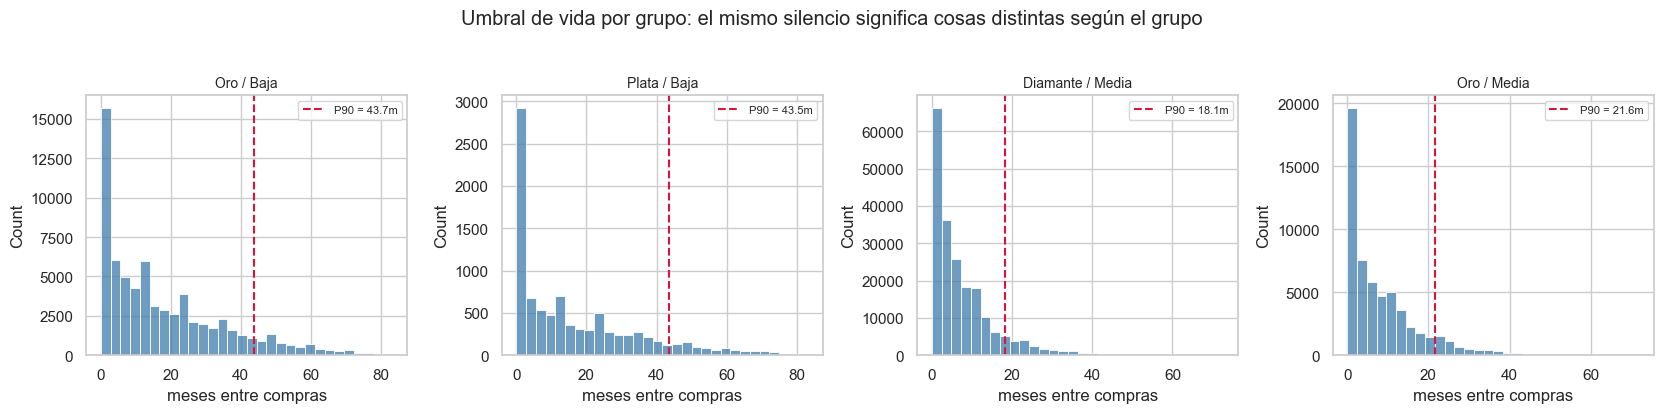

In [13]:
grupos_top = clientes["GrupoEstructural"].value_counts().head(4).index.tolist()
fig, axes = plt.subplots(1, len(grupos_top), figsize=(4.2 * len(grupos_top), 4), sharey=False)
if len(grupos_top) == 1:
    axes = [axes]

for ax, grupo in zip(axes, grupos_top):
    datos = intervalos.loc[intervalos["GrupoEstructural"] == grupo, "Intervalo_Meses"]
    u = umbrales.loc[umbrales["GrupoEstructural"] == grupo, "Umbral_Meses"].iloc[0]
    sns.histplot(datos, bins=30, ax=ax, color="#3f7cac")
    ax.axvline(u, color="crimson", linestyle="--", label=f"P{PERCENTIL_UMBRAL} = {u:.1f}m")
    ax.set_title(grupo, fontsize=10)
    ax.set_xlabel("meses entre compras")
    ax.legend(fontsize=8)

fig.suptitle("Umbral de vida por grupo: el mismo silencio significa cosas distintas según el grupo", y=1.03)
fig.tight_layout()
fig.savefig("grafico_5_umbrales_por_grupo.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Capa de estado: Activo / Por inactivar / Inactivo

Se compara la recencia de cada cliente contra el umbral de **su propio** grupo estructural.

In [14]:
clientes = clientes.merge(umbrales[["GrupoEstructural", "Umbral_Meses", "Confiable"]], on="GrupoEstructural", how="left")
clientes["Umbral_Meses"] = clientes["Umbral_Meses"].fillna(umbral_global)


def calcular_estado(row):
    rec, u = row["RecenciaMeses"], row["Umbral_Meses"]
    if rec < CORTE_ACTIVO * u:
        return "Activo"
    elif rec <= u:
        return "Por inactivar"
    else:
        return "Inactivo"


clientes["Estado"] = clientes.apply(calcular_estado, axis=1)
clientes["Estado"].value_counts()

Estado
Inactivo         114783
Activo           109394
Por inactivar     49340
Name: count, dtype: int64

**Gráfico 6.** Reparto de estado en clientes y en margen — la lectura "fotograma" que necesita el CRM, hoy.

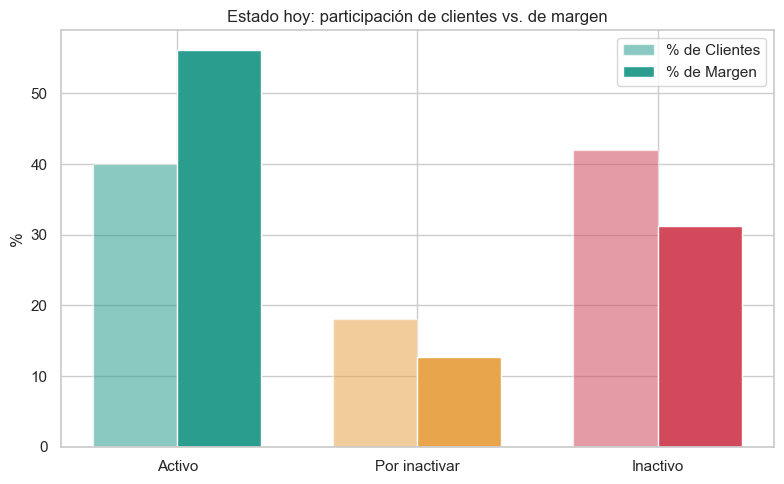

,Clientes,Margen,%Clientes,%Margen
Estado,,,,
Activo,109394,6.972340e+10,40.0,56.1
Por inactivar,49340,1.582838e+10,18.0,12.7
Inactivo,114783,3.875195e+10,42.0,31.2


In [15]:
orden_estado = ["Activo", "Por inactivar", "Inactivo"]
colores_estado = {"Activo": "#2a9d8f", "Por inactivar": "#e9a54c", "Inactivo": "#d1495b"}

resumen_estado = (
    clientes.groupby("Estado")
    .agg(Clientes=("ID_Cliente_Unico", "count"), Margen=("Valor", "sum"))
    .reindex(orden_estado)
)
resumen_estado["%Clientes"] = resumen_estado["Clientes"] / resumen_estado["Clientes"].sum() * 100
resumen_estado["%Margen"] = resumen_estado["Margen"] / resumen_estado["Margen"].sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(orden_estado))
width = 0.35
ax.bar(x - width / 2, resumen_estado["%Clientes"], width, label="% de Clientes",
       color=[colores_estado[e] for e in orden_estado], alpha=0.55)
ax.bar(x + width / 2, resumen_estado["%Margen"], width, label="% de Margen",
       color=[colores_estado[e] for e in orden_estado])
ax.set_xticks(x)
ax.set_xticklabels(orden_estado)
ax.set_ylabel("%")
ax.set_title("Estado hoy: participación de clientes vs. de margen")
ax.legend()
fig.tight_layout()
fig.savefig("grafico_6_estado_hoy.png", dpi=150, bbox_inches="tight")
plt.show()

resumen_estado.round(1)

## 11. Resumen para el equipo

In [16]:
grupo_top_margen = clientes.groupby("GrupoEstructural")["Valor"].sum().idxmax()
pct_margen_top = clientes.groupby("GrupoEstructural")["Valor"].sum().max() / clientes["Valor"].sum() * 100
pct_clientes_top = (clientes["GrupoEstructural"] == grupo_top_margen).mean() * 100
grupos_no_confiables = umbrales.loc[~umbrales["Confiable"], "GrupoEstructural"].tolist()

ajuste_valor = " (ajustado manualmente)" if K_VALOR != k_valor else ""
ajuste_frec = " (ajustado manualmente)" if K_FRECUENCIA != k_frecuencia else ""

print("RESUMEN PARA EL EQUIPO")
print("=" * 60)
print(f"- Eje de Valor: el codo sugirió {k_valor} niveles; se usaron {K_VALOR}{ajuste_valor} -> {orden_metales}")
print(f"- Eje de Frecuencia: el codo sugirió {k_frecuencia} niveles; se usaron {K_FRECUENCIA}{ajuste_frec} -> {orden_niveles_frec}")
print(f"- Cruce de ejes: {K_VALOR * K_FRECUENCIA} grupos estructurales posibles")
print(f"- El grupo '{grupo_top_margen}' es el {pct_clientes_top:.1f}% de los clientes")
print(f"  pero concentra el {pct_margen_top:.1f}% del margen total.")
print(f"- Hoy: {resumen_estado.loc['Activo','%Clientes']:.1f}% de los clientes están Activos")
print(f"  ({resumen_estado.loc['Activo','%Margen']:.1f}% del margen), "
      f"{resumen_estado.loc['Inactivo','%Clientes']:.1f}% Inactivos.")
if grupos_no_confiables:
    print(f"- Umbral poco confiable (menos de {MIN_INTERVALOS_CONFIABLE} intervalos observados) en: {grupos_no_confiables}")
    print(f"  Se usó el umbral global ({umbral_global:.1f} meses) como respaldo en esos grupos.")
print("- Gráficos guardados en esta carpeta: grafico_1 a grafico_6 (.png).")

RESUMEN PARA EL EQUIPO
- Eje de Valor: el codo sugirió 2 niveles; se usaron 3 (ajustado manualmente) -> ['Diamante', 'Oro', 'Plata']
- Eje de Frecuencia: el codo sugirió 2 niveles; se usaron 3 (ajustado manualmente) -> ['Alta', 'Media', 'Baja']
- Cruce de ejes: 9 grupos estructurales posibles
- El grupo 'Diamante / Media' es el 12.0% de los clientes
  pero concentra el 33.4% del margen total.
- Hoy: 40.0% de los clientes están Activos
  (56.1% del margen), 42.0% Inactivos.
- Gráficos guardados en esta carpeta: grafico_1 a grafico_6 (.png).


## 12. Resultado final por Cliente

In [17]:
df_master = leer_con_reintentos("""
SELECT Cliente, ID_Cliente_Unico
FROM Ventas_Comerssia.dbo.MASTER_ID
""", engine)

resultado_final = df_master.merge(
    clientes[[
        "ID_Cliente_Unico", "CosechaFecha", "UltimaCompra", "Valor", "Frecuencia",
        "Metal", "NivelFrecuencia", "GrupoEstructural", "RecenciaMeses", "Umbral_Meses", "Estado",
    ]],
    on="ID_Cliente_Unico",
    how="inner",
)

# Filtro de seguridad: un ID_Cliente_Unico puede tener mezclado un Cliente real con uno
# genérico (ej. ID 206829 mezclaba a Catalina Gómez Barrera con "Consumidor Final"); el
# join anterior es por ID_Cliente_Unico, así que aquí se quita explícitamente cualquier
# código de Cliente genérico que se haya colado.
antes = len(resultado_final)
resultado_final = resultado_final[~resultado_final["Cliente"].isin(CLIENTES_EXCLUIR)].reset_index(drop=True)
if antes != len(resultado_final):
    print(f"Filas de Cliente genérico quitadas del resultado final: {antes - len(resultado_final):,}")

print(f"Total filas (clientes): {len(resultado_final):,}")
resultado_final.head(20)

Filas de Cliente genérico quitadas del resultado final: 1
Total filas (clientes): 290,656


,Cliente,ID_Cliente_Unico,CosechaFecha,UltimaCompra,Valor,Frecuencia,Metal,NivelFrecuencia,GrupoEstructural,RecenciaMeses,Umbral_Meses,Estado
0,C1001191851,493874,2026-06-20,2026-06-20,77387.7698,5.072917,Plata,Alta,Plata / Alta,2.365309,4.793035,Activo
1,C1006993270,493875,2026-06-20,2026-06-20,227846.4198,5.072917,Oro,Alta,Oro / Alta,2.365309,6.668857,Activo
2,C1020829429,493880,2026-06-19,2026-06-19,139887.2601,5.003425,Oro,Alta,Oro / Alta,2.398160,6.668857,Activo
3,C1015413107,493882,2026-06-19,2026-06-19,107786.2959,5.003425,Oro,Alta,Oro / Alta,2.398160,6.668857,Activo
4,C1018462550,493883,2026-06-21,2026-06-21,42671.0587,5.144366,Plata,Alta,Plata / Alta,2.332457,4.793035,Activo
5,C1014869550,493885,2026-06-20,2026-06-20,144108.9775,5.072917,Oro,Alta,Oro / Alta,2.365309,6.668857,Activo
6,C1010014340,493887,2026-06-20,2026-07-26,214520.4134,10.145833,Oro,Alta,Oro / Alta,1.182654,6.668857,Activo
7,C1032424152,493888,2026-06-19,2026-06-19,34143.1920,5.003425,Plata,Alta,Plata / Alta,2.398160,4.793035,Activo
8,C1007642609,493889,2026-06-20,2026-06-20,58279.6491,5.072917,Plata,Alta,Plata / Alta,2.365309,4.793035,Activo
9,C1031651885,493890,2026-06-19,2026-06-19,163440.9572,5.003425,Oro,Alta,Oro / Alta,2.398160,6.668857,Activo


## 13. Exportar resultados

In [18]:
with pd.ExcelWriter("segmentacion_valor_frecuencia.xlsx") as writer:
    resultado_final.to_excel(writer, sheet_name="Clientes", index=False)
    umbrales.to_excel(writer, sheet_name="Umbrales_Grupo", index=False)
    resumen_estado.round(1).to_excel(writer, sheet_name="Resumen_Estado")

print("Exportado: segmentacion_valor_frecuencia.xlsx (hojas: Clientes, Umbrales_Grupo, Resumen_Estado)")
print("Gráficos exportados como PNG en esta misma carpeta (grafico_1 ... grafico_6)")

# Descomentar para escribir en SQL Server (crea/reemplaza la tabla Segmentacion_ValorFrecuencia)
# resultado_final.to_sql("Segmentacion_ValorFrecuencia", engine, if_exists="replace", index=False)

Exportado: segmentacion_valor_frecuencia.xlsx (hojas: Clientes, Umbrales_Grupo, Resumen_Estado)
Gráficos exportados como PNG en esta misma carpeta (grafico_1 ... grafico_6)


## 14. Curva de LTV por cohorte (grupo estructural)

Esta es la pieza que le faltaba a este análisis: la curva de margen acumulado promedio
por mes de vida, para cada grupo estructural. Se apoya en `df_ventas`, `clientes` y
`fecha_corte` que ya están calculados arriba -- no se recalculan Valor, Frecuencia,
Estado ni los umbrales, y no se vuelve a consultar la base de datos.

El punto central de esta construcción es la **censura por madurez** (Paso 3): un
cliente que entró hace 3 meses no puede "opinar" sobre cómo se ve el mes de vida 24,
porque todavía no ha vivido esos 24 meses. Si se le incluyera de todas formas (con su
margen actual, que es todo lo que tiene hasta ahora), el promedio de esa cohorte en
los meses altos quedaría sesgado hacia abajo -- solo porque los clientes recientes
"prestan" un valor bajo a un punto de la curva que en realidad no les corresponde
todavía. Por eso cada cliente solo aporta filas hasta el mes de vida que realmente
ha alcanzado para `fecha_corte`.

In [ ]:
# --- Paso 1: Mes de vida por transacción ---
# Copia de trabajo (no se modifica df_ventas original). MesVida = meses completos
# transcurridos entre la cosecha del cliente y cada transacción suya.
ventas_ltv = df_ventas.merge(
    clientes[["ID_Cliente_Unico", "CosechaFecha"]],
    on="ID_Cliente_Unico",
    how="inner",
)
ventas_ltv["MesVida"] = np.floor(
    (ventas_ltv["Fecha"] - ventas_ltv["CosechaFecha"]).dt.days / 30.44
)

filas_negativas = int((ventas_ltv["MesVida"] < 0).sum())
if filas_negativas:
    print(f"Filas excluidas por MesVida negativo (venta registrada antes de la cosecha, error de datos): {filas_negativas:,}")

ventas_ltv = ventas_ltv[ventas_ltv["MesVida"] >= 0].copy()
ventas_ltv["MesVida"] = ventas_ltv["MesVida"].astype(int)
print(f"Filas para la curva de LTV: {len(ventas_ltv):,}")

### Paso 2 y 3: margen acumulado por cliente y mes de vida, con censura por madurez

Primero se calcula el margen acumulado de cada cliente en los meses de vida donde
tuvo transacciones (Paso 2). Después se construye una grilla explícita: cada cliente
aporta exactamente una fila por cada mes de vida entre 0 y su `MesesVidaActual`
(cuántos meses de vida ha alcanzado ya para `fecha_corte`) -- ni uno más, ni uno
menos. En los meses donde no compró, su margen acumulado se arrastra del último mes
en que sí tuvo movimiento (forward-fill), porque el margen acumulado no baja solo
por no comprar; solo se actualiza cuando hay una transacción nueva.

In [ ]:
# --- Paso 2: margen acumulado por cliente en los meses de vida con transacción ---
margen_mes = (
    ventas_ltv.groupby(["ID_Cliente_Unico", "MesVida"])["Margen"].sum()
    .groupby(level=0).cumsum()
    .reset_index(name="MargenAcumulado")
)

# --- Paso 3: censura por madurez ---
# MesesVidaActual = cuántos meses de vida ha alcanzado ya cada cliente para fecha_corte.
clientes_ltv = clientes[["ID_Cliente_Unico", "CosechaFecha", "GrupoEstructural", "Metal", "NivelFrecuencia"]].copy()
clientes_ltv["MesesVidaActual"] = np.floor(
    (fecha_corte - clientes_ltv["CosechaFecha"]).dt.days / 30.44
).astype(int)

# Grilla: cada cliente aporta una fila por cada mes de vida de 0 a MesesVidaActual
# (un cliente con MesesVidaActual=5 aporta exactamente 6 filas, M=0..5).
n_meses = clientes_ltv["MesesVidaActual"].to_numpy() + 1
grid = pd.DataFrame({
    "ID_Cliente_Unico": np.repeat(clientes_ltv["ID_Cliente_Unico"].to_numpy(), n_meses),
    "MesVida": np.concatenate([np.arange(m) for m in n_meses]),
})

curva = grid.merge(margen_mes, on=["ID_Cliente_Unico", "MesVida"], how="left")
curva = curva.merge(
    clientes_ltv[["ID_Cliente_Unico", "GrupoEstructural", "Metal", "NivelFrecuencia"]],
    on="ID_Cliente_Unico", how="left",
)
# Forward-fill dentro de cada cliente: si no compró ese mes, se arrastra el acumulado anterior.
curva = curva.sort_values(["ID_Cliente_Unico", "MesVida"])
curva["MargenAcumulado"] = curva.groupby("ID_Cliente_Unico")["MargenAcumulado"].ffill().fillna(0)

print(f"Filas de la grilla cliente x mes de vida: {len(curva):,}")

### Paso 4: promedio por grupo, con el denominador correcto

Al promediar el margen acumulado por `GrupoEstructural` y `MesVida`, el denominador
(`n_clientes`) es el número de clientes del grupo que alcanzaron ese mes de vida --
la grilla del paso anterior ya garantiza que un cliente de compra única sigue
apareciendo (con su curva plana, arrastrada) en todos los meses hasta su
`MesesVidaActual`, así que no hace falta ni hay que excluirlo aparte.

In [ ]:
# --- Paso 4: promedio por grupo estructural y mes de vida ---
curva_grupo = (
    curva.groupby(["Metal", "NivelFrecuencia", "GrupoEstructural", "MesVida"])
    .agg(
        MargenAcumuladoProm=("MargenAcumulado", "mean"),
        n_clientes=("ID_Cliente_Unico", "count"),
    )
    .reset_index()
    .sort_values(["GrupoEstructural", "MesVida"])
)
curva_grupo.head(10)

### Paso 5: tabla y gráfica, cortando donde ya no hay soporte suficiente

Se reutiliza `MIN_INTERVALOS_CONFIABLE` (el mismo umbral de confiabilidad que ya usan
los umbrales de estado) como número mínimo de clientes para confiar en un punto de la
curva. Como `n_clientes` solo puede bajar a medida que aumenta `MesVida` (cada mes
adicional exige haber vivido más), basta con encontrar el último mes de vida por
grupo donde todavía se cumple el mínimo, y cortar ahí -- en vez de dejar que la curva
seguir hasta quedar sostenida por un puñado de clientes.

In [ ]:
# --- Paso 5a: cortar cada grupo en el último mes de vida con soporte suficiente ---
MIN_CLIENTES_LTV = MIN_INTERVALOS_CONFIABLE  # mismo umbral de confiabilidad que ya usa el notebook

mes_max_confiable = (
    curva_grupo.loc[curva_grupo["n_clientes"] >= MIN_CLIENTES_LTV]
    .groupby("GrupoEstructural")["MesVida"].max()
    .rename("MesVidaMax")
)
curva_grupo = curva_grupo.merge(mes_max_confiable, on="GrupoEstructural", how="left")
curva_grupo_confiable = curva_grupo[curva_grupo["MesVida"] <= curva_grupo["MesVidaMax"]].drop(columns="MesVidaMax").reset_index(drop=True)

print(f"Meses de vida con soporte >= {MIN_CLIENTES_LTV} clientes, por grupo:")
print(mes_max_confiable.sort_values())

In [ ]:
# --- Paso 5b: gráfica -- una figura por Metal, una línea por NivelFrecuencia ---
colores_nivel = dict(zip(orden_niveles_frec, sns.color_palette("Set2", len(orden_niveles_frec))))
metales_con_datos = [m for m in orden_metales if m in curva_grupo_confiable["Metal"].unique()]

fig, axes = plt.subplots(1, len(metales_con_datos), figsize=(5.5 * len(metales_con_datos), 4.5), sharey=True)
if len(metales_con_datos) == 1:
    axes = [axes]

for ax, metal in zip(axes, metales_con_datos):
    datos_metal = curva_grupo_confiable[curva_grupo_confiable["Metal"] == metal]
    for nivel in orden_niveles_frec:
        datos_linea = datos_metal[datos_metal["NivelFrecuencia"] == nivel].sort_values("MesVida")
        if datos_linea.empty:
            continue
        ax.plot(
            datos_linea["MesVida"], datos_linea["MargenAcumuladoProm"],
            marker="o", markersize=3, color=colores_nivel[nivel], label=nivel,
        )
    ax.set_title(metal)
    ax.set_xlabel("Mes de vida")
    ax.legend(title="Frecuencia", fontsize=8)

axes[0].set_ylabel("Margen acumulado promedio")
fig.suptitle(f"Curva de LTV por cohorte (grupos truncados bajo {MIN_CLIENTES_LTV} clientes de soporte)", y=1.03)
fig.tight_layout()
fig.savefig("grafico_7_curva_ltv.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Exportar la curva de LTV

Se agrega como una hoja nueva (`Curva_LTV`) al mismo Excel que ya exporta el resto
del notebook -- no se vuelve a escribir sobre las hojas `Clientes`, `Umbrales_Grupo`
ni `Resumen_Estado`.

In [ ]:
# --- Paso 6: exportar ---
with pd.ExcelWriter("segmentacion_valor_frecuencia.xlsx", mode="a", engine="openpyxl", if_sheet_exists="replace") as writer:
    curva_grupo_confiable.to_excel(writer, sheet_name="Curva_LTV", index=False)

print("Hoja 'Curva_LTV' agregada a segmentacion_valor_frecuencia.xlsx")
print("Gráfico guardado: grafico_7_curva_ltv.png")